John S. Anvik, 2026  
University of Lethbridge Student ID: 001224816

In [240]:
# A lookup table to easily access IDs /ID numbers for each neighbourhood
focal_males <- tibble::tribble(
    ~neighbourhood, ~male_number, ~ID,
    "north",  "1", "LbOW",
    "north",  "2", "RbDgY",
    "north",  "3", "YKY",
    "north",  "4", "TbTbLg",
    "north",  "5", "DgTbO",
    "north",  "6", "RRO",
    "centre", "1", "TbWY",
    "centre", "2", "KRDg",
    # "centre", "3", "OPR",
    "centre", "4", "WLpTb",
    "centre", "5", "KLgK",
    "centre", "6", "DgTbO"
)

In [241]:
# load packages
install.packages("tidyverse")
library(tidyverse)
library(tidymodels)
theme_dark()
# set random seed
set.seed(42)

Warning message:
"package 'tidyverse' is in use and will not be installed"


<theme> List of 144
 $ line                            : <ggplot2::element_line>
  ..@ colour       : chr "black"
  ..@ linewidth    : num 0.5
  ..@ linetype     : num 1
  ..@ lineend      : chr "butt"
  ..@ linejoin     : chr "round"
  ..@ arrow        : logi FALSE
  ..@ arrow.fill   : chr "black"
  ..@ inherit.blank: logi TRUE
 $ rect                            : <ggplot2::element_rect>
  ..@ fill         : chr "white"
  ..@ colour       : chr "black"
  ..@ linewidth    : num 0.5
  ..@ linetype     : num 1
  ..@ linejoin     : chr "round"
  ..@ inherit.blank: logi TRUE
 $ text                            : <ggplot2::element_text>
  ..@ family       : chr ""
  ..@ face         : chr "plain"
  ..@ italic       : chr NA
  ..@ fontweight   : num NA
  ..@ fontwidth    : num NA
  ..@ colour       : chr "black"
  ..@ size         : num 11
  ..@ hjust        : num 0.5
  ..@ vjust        : num 0.5
  ..@ angle        : num 0
  ..@ lineheight   : num 0.9
  ..@ margin       : <ggplot2::margin> nu

In [242]:
# Fall 2026 results

test_accuracies <- list()
song_accuracies <- list()

folder_path <- "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\2026_results"
files = list.files(folder_path, full.names=TRUE)

for (file in files) {
    print(file)
    name <- as.character(file)
    if (str_detect(file, "test_accuracies")) {
        test_accuracies <- append(test_accuracies, list("{name}" = read_csv(file)))
    } else if (str_detect(file, "song_accuracies")) {
        song_accuracies <- append(song_accuracies, list("{file}" = read_csv(file)))
    }
}

test_accuracies <- bind_rows(test_accuracies)
song_accuracies <- bind_rows(song_accuracies)

test_accuracies <- song_accuracies %>% group_by(ID) %>% summarize(repertoire_size = n_distinct(UST)) %>% 
    full_join(test_accuracies, by=join_by(ID)) %>%
    left_join(focal_males, by="ID")

[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\2026_results/logit_All_neighbour_features_song_accuracies.csv"


Rows: 192 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (3): UST, estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\2026_results/logit_All_neighbour_features_test_accuracies.csv"


Rows: 11 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (2): estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\2026_results/logit_Baseline_most_common_song_song_accuracies.csv"


Rows: 192 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (3): UST, estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


... (30 outputs left out)

[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\2026_results/logit_Song_type_rates_song_accuracies.csv"


Rows: 192 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (3): UST, estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\2026_results/logit_Song_type_rates_test_accuracies.csv"


Rows: 11 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (2): estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [243]:
# Winter 2026 Results (last semester)

test_accuracies_2026 <- list()
song_accuracies_2026 <- list()

folder_path <- "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results"
files = list.files(folder_path, full.names=TRUE)

for (file in files) {
    print(file)
    name <- as.character(file)
    if (str_detect(file, "test_accuracies")) {
        test_accuracies_2026 <- append(test_accuracies_2026, list("{name}" = read_csv(file)))
    } else if (str_detect(file, "song_accuracies")) {
        song_accuracies_2026 <- append(song_accuracies_2026, list("{file}" = read_csv(file)))
    }
}

test_accuracies_2026 <- bind_rows(test_accuracies_2026)
song_accuracies_2026 <- bind_rows(song_accuracies_2026)

test_accuracies_2026 <- song_accuracies_2026 %>% group_by(ID) %>% summarize(repertoire_size = n_distinct(UST)) %>% 
    full_join(test_accuracies, by=join_by(ID)) %>%
    left_join(focal_males, by="ID")

# Select only models featured in Winter 2026 report
report_models_2026 <- c(
    "Baseline Classifier",
    "Own Song History",
    "Own Last Songs",
    "Last Song from Each Neighbour",
    "All songs since last own song",
    "All songs in last 60s",
    "Attention",
    "Attention 30s",
    "Most Common Songs"
)

test_accuracies_2026 <- test_accuracies_2026 %>% filter(model %in% report_models_2026)
song_accuracies_2026 <- song_accuracies_2026 %>% filter(model %in% report_models_2026)

[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/Baseline Classifier_test_accuracies.csv"


Rows: 10 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): ID, model, model_type
dbl (1): estimated_accuracy

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/N greater than 30 Baseline Classifier_test_accuracies.csv"


Rows: 10 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): ID, model, model_type
dbl (1): estimated_accuracy

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/rf_All songs in last 60s_song_accuracies.csv"


Rows: 201 Columns: 6
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): ID, model, model_type
dbl (3): UST, estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


... (52 outputs left out)

[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/rf_True Attention_test_accuracies.csv"


Rows: 11 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): ID, model, model_type
dbl (1): estimated_accuracy

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/Top 5 Classes Baseline Classifier_test_accuracies.csv"


Rows: 10 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): ID, model, model_type
dbl (1): estimated_accuracy

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [244]:
test_accuracies %>% pull(model) %>% unique()

[1] "All neighbour features"                       
 [2] "Baseline most common song"                    
 [3] "Neighbours only"                              
 [4] "Own history and both neighbour counts"        
 [5] "Own history and neighbour counts"             
 [6] "Own history and weighted neighbour counts"    
 [7] "Own history and weighted neighbour last songs"
 [8] "Own repeat"                                   
 [9] "Own song history"                             
[10] "Song type rates"

In [245]:
# report_models <- c(
#     "Baseline Classifier",
#     "Own Song History",
#     "Own Last Songs",
#     "Last Song from Each Neighbour",
#     "All songs since last own song",
#     "All songs in last 60s",
#     "Attention",
#     "Attention 30s",
#     "Most Common Songs"
# )
report_models <- unique(song_accuracies$model)

In [246]:
c(report_models)

[1] "All neighbour features"                       
 [2] "Baseline most common song"                    
 [3] "Neighbours only"                              
 [4] "Own history and both neighbour counts"        
 [5] "Own history and neighbour counts"             
 [6] "Own history and weighted neighbour counts"    
 [7] "Own history and weighted neighbour last songs"
 [8] "Own repeat"                                   
 [9] "Own song history"                             
[10] "Song type rates"

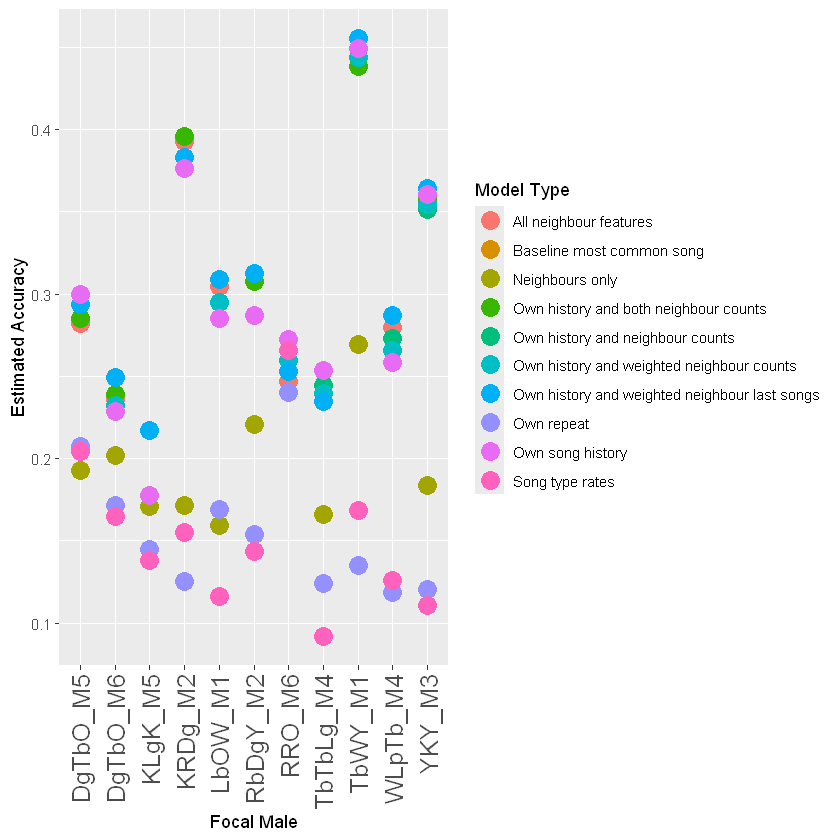

In [249]:
# TODO: Throw in baseline classifer
plot <- ggplot(data = test_accuracies %>% filter(model %in% report_models), aes(x=ID, y=estimated_accuracy, color=model)) +
    geom_point(size=5) +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) + # making x axis labels vertical
    labs(x="Focal Male", y= "Estimated Accuracy", colour="Model Type")
print(plot)

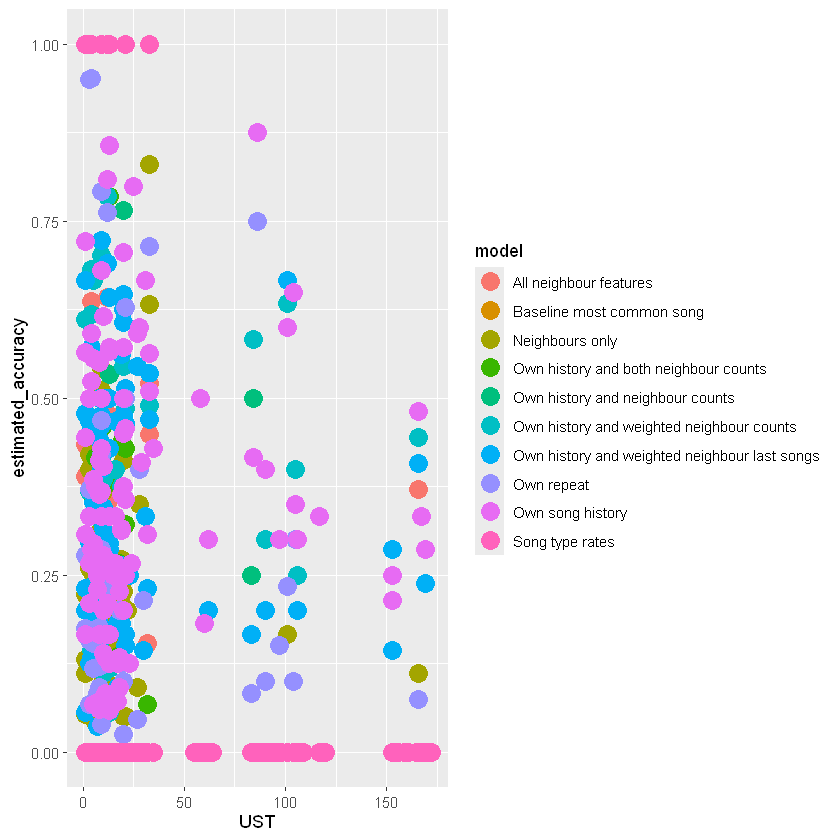

In [250]:

plot <- ggplot(data = song_accuracies, aes(x=UST, y=estimated_accuracy, color=model)) +
    geom_point(size=5)
print(plot)

Warning message:
"The shape palette can deal with a maximum of 6 discrete values because more
than 6 becomes difficult to discriminate
ℹ you have requested 10 values. Consider specifying shapes manually if you need
  that many of them."
Warning message:
"Removed 768 rows containing missing values or values outside the scale range
(`geom_point()`)."


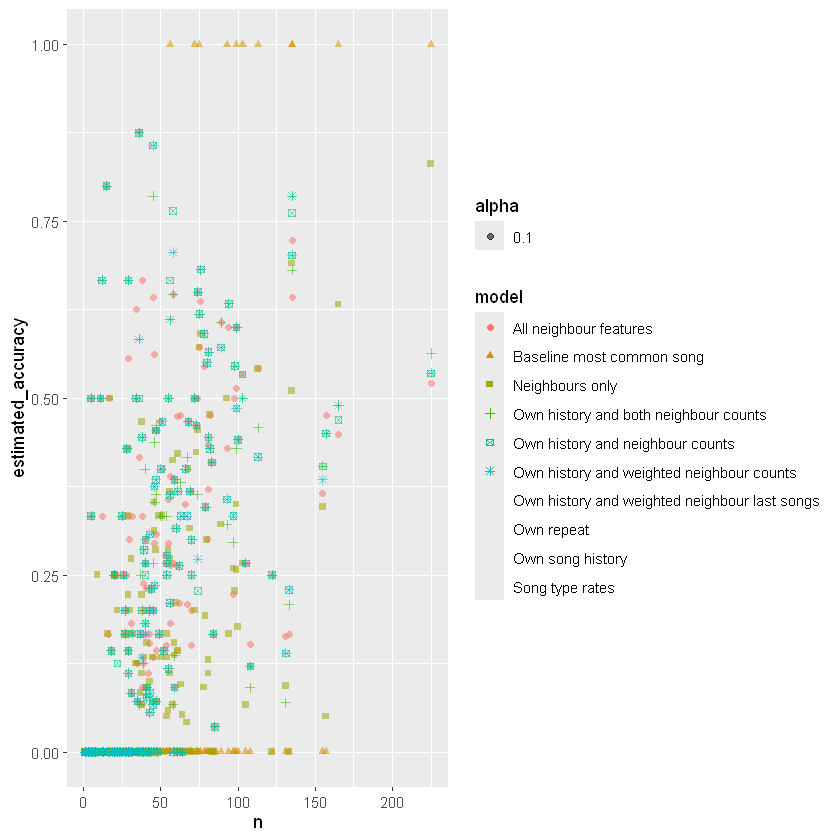

In [251]:
plot <- ggplot(data=song_accuracies) + 
    aes(x=n, y=estimated_accuracy, color=model, shape=model, alpha=0.1) +
    geom_point()
print(plot)

Ignoring unknown labels:
• colour : "Focal Male"


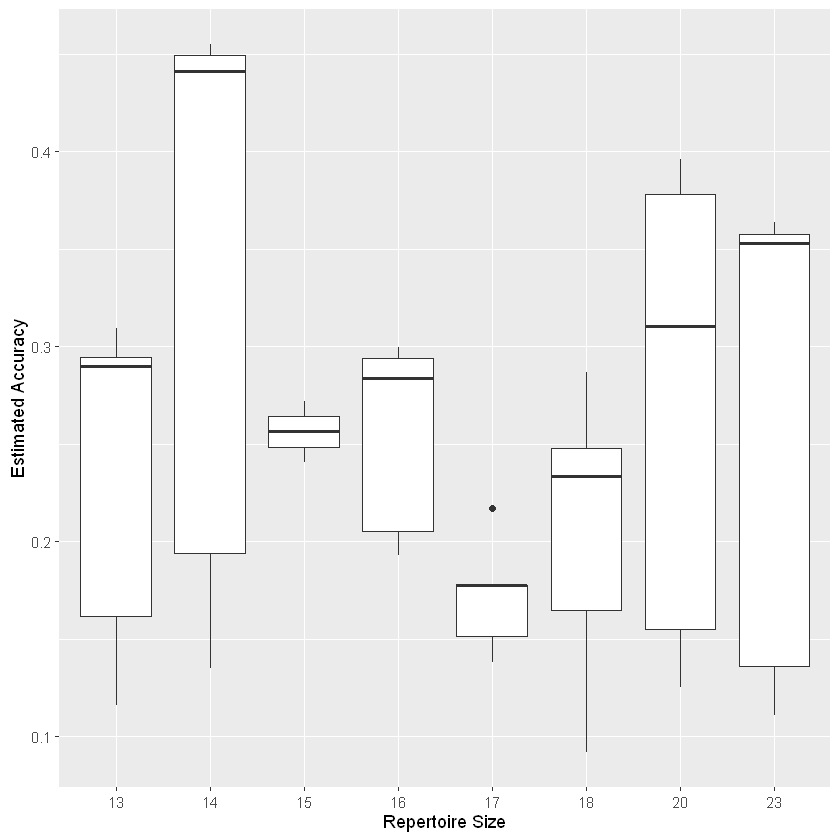

In [252]:
ggplot(test_accuracies %>% filter(model %in% report_models) %>% mutate(repertoire_size = as.factor(repertoire_size)), aes(x=repertoire_size, y=estimated_accuracy)) +
    geom_boxplot() +
    labs(x="Repertoire Size", y = "Estimated Accuracy", color='Focal Male')

In [253]:
# TODO: Results don't have neighbourhood column
# ggplot(test_accuracies %>% filter(model %in% report_models) %>% filter(neighbourhood == "north") %>% mutate(repertoire_size = as.factor(repertoire_size)), aes(x=repertoire_size, y=estimated_accuracy)) +
#     geom_boxplot() +
#     labs(x="Repertoire Size", y = "Estimated Accuracy", color='Focal Male', title="Repertoire Size vs Model Accuracy (North Neighbourhood)")

In [254]:
# TODO: Results don't have neighbourhood column
# # ggplot(test_accuracies %>% filter(model %in% report_models) %>% filter(neighbourhood == "centre") %>% mutate(repertoire_size = as.factor(repertoire_size)), aes(x=repertoire_size, y=estimated_accuracy)) +
#     geom_boxplot() +
#     labs(x="Repertoire Size", y = "Estimated Accuracy", color='Focal Male', title="Repertoire Size vs Model Accuracy (Centre Neighbourhood)")

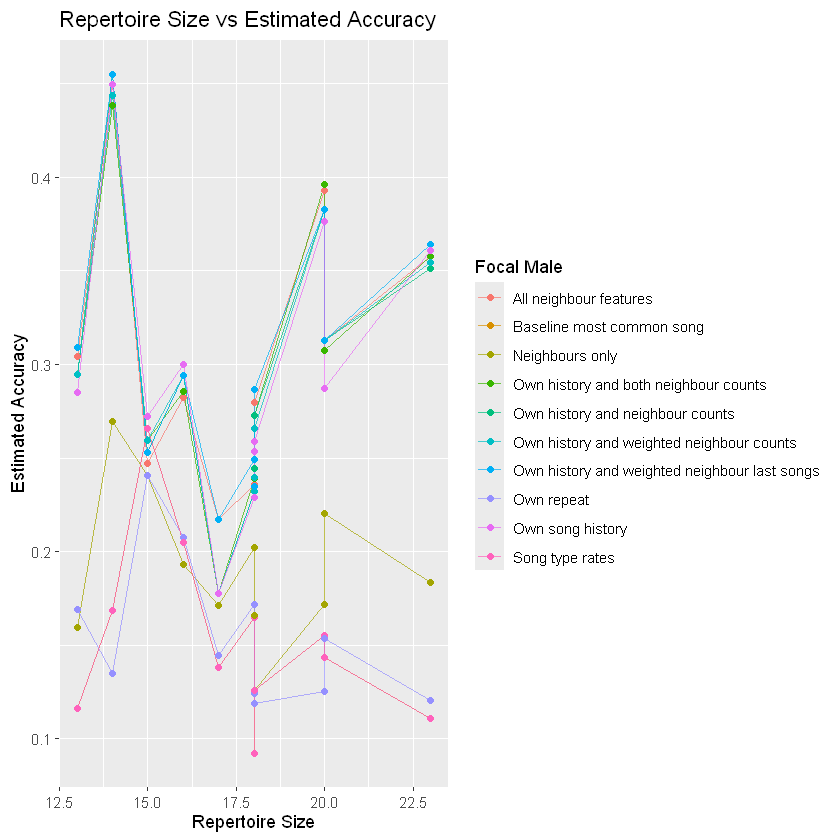

In [255]:
ggplot(test_accuracies %>% filter(model %in% report_models), aes(x=repertoire_size, y=estimated_accuracy, color=model)) +
    geom_line(alpha=0.7) +
    geom_point() +
    labs(x="Repertoire Size", y = "Estimated Accuracy", color='Focal Male', title="Repertoire Size vs Estimated Accuracy")

In [256]:
unique(song_accuracies$model)

[1] "All neighbour features"                       
 [2] "Baseline most common song"                    
 [3] "Neighbours only"                              
 [4] "Own history and both neighbour counts"        
 [5] "Own history and neighbour counts"             
 [6] "Own history and weighted neighbour counts"    
 [7] "Own history and weighted neighbour last songs"
 [8] "Own repeat"                                   
 [9] "Own song history"                             
[10] "Song type rates"

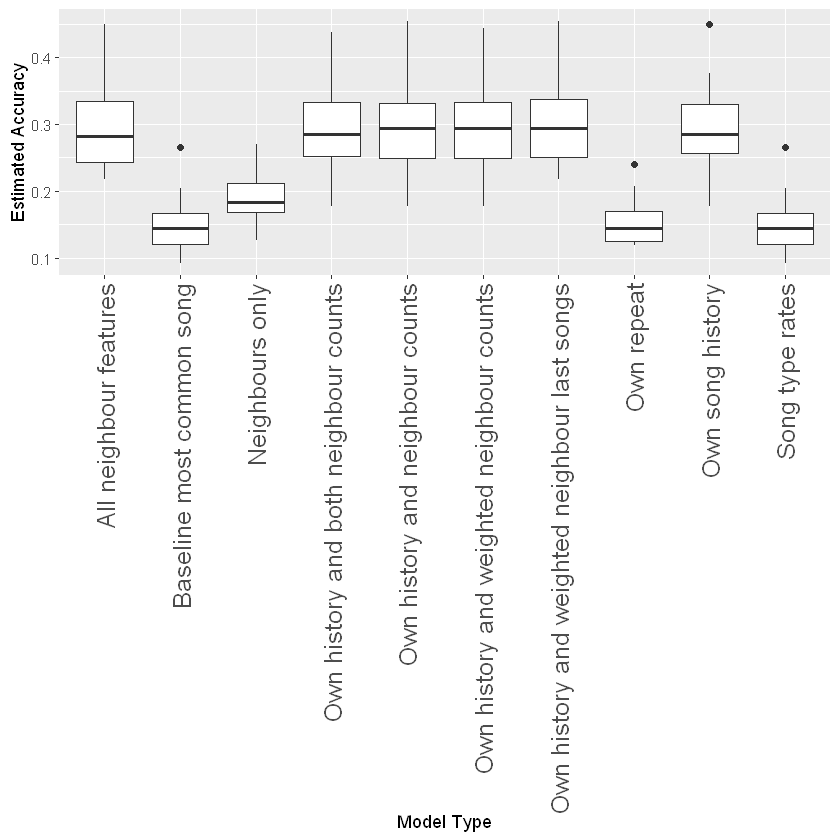

In [257]:
# Accuracy distribution of each model type
ggplot(data=test_accuracies %>% filter(model %in% report_models)) +
    aes(x=model, y=estimated_accuracy) + 
    geom_boxplot() +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) + # making x axis labels vertical 
    labs(x="Model Type", y="Estimated Accuracy")

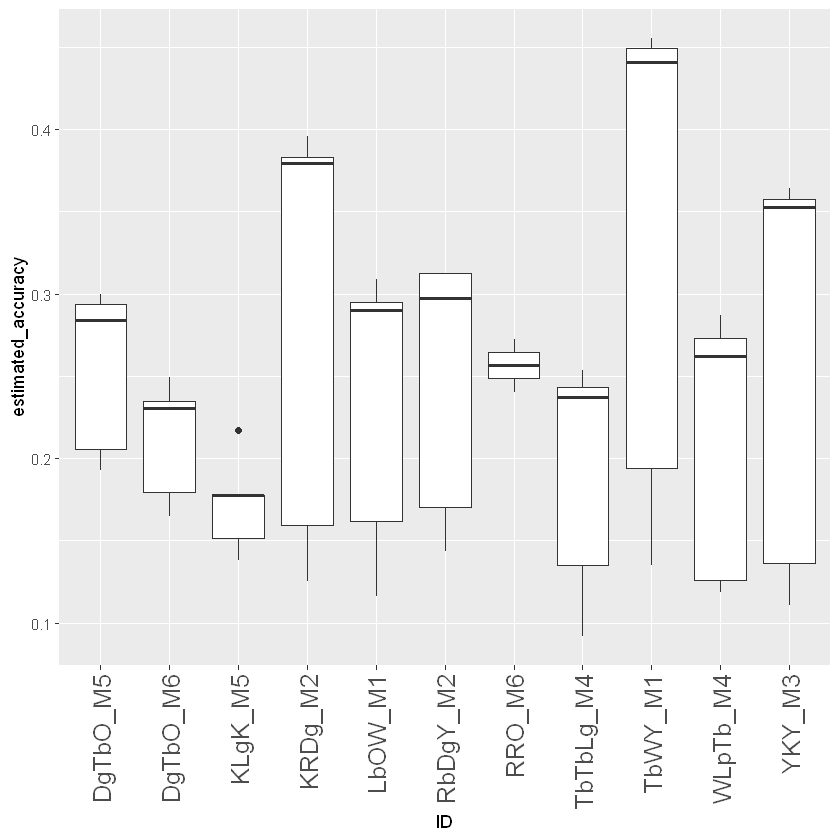

In [258]:
# Accuracy distribution of each focal male
ggplot(data=test_accuracies %>% filter(model %in% report_models)) +
    aes(x=ID, y=estimated_accuracy) + 
    geom_boxplot() +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) # making x axis labels vertical

In [259]:
# TODO: Add neighbourhood column
# # Accuracy distribution of each focal male
# ggplot(data=test_accuracies %>% filter(model %in% report_models, neighbourhood=="north")) +
#     aes(x=ID, y=estimated_accuracy) + 
#     geom_boxplot() +
#     theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) # making x axis labels vertical

In [260]:
# TODO: Add neighbourhood column
# # Accuracy distribution of each focal male
# ggplot(data=test_accuracies %>% filter(model %in% report_models, neighbourhood=="centre")) +
#     aes(x=ID, y=estimated_accuracy) + 
#     geom_boxplot() +
#     theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) # making x axis labels vertical

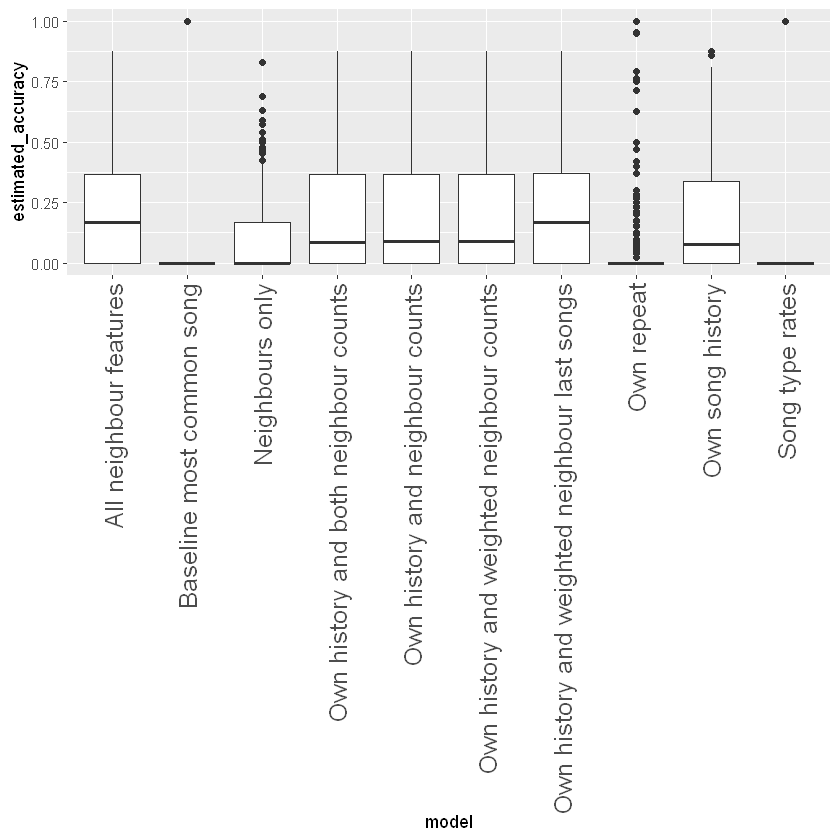

In [261]:
# Accuracy distribution of song types according to models
ggplot(data=song_accuracies) +
    aes(x=model, y=estimated_accuracy) + 
    geom_boxplot() +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) # making x axis labels vertical

In [262]:
test_accuracies %>% group_by(ID) %>% summarize(mean_accuracy = mean(estimated_accuracy)) %>% arrange(desc(mean_accuracy))

ID,mean_accuracy
<chr>,<dbl>
TbWY_M1,0.3432584
KRDg_M2,0.2920792
YKY_M3,0.2670886
DgTbO_M5,0.2559078
RRO_M6,0.2556962
RbDgY_M2,0.2507692
LbOW_M1,0.2342995
WLpTb_M4,0.2132867
DgTbO_M6,0.2121212


In [263]:
test_accuracies %>% group_by(model) %>% summarize(mean_accuracy = mean(estimated_accuracy)) %>% arrange(desc(mean_accuracy))

model,mean_accuracy
<chr>,<dbl>
Own history and weighted neighbour last songs,0.3053573
All neighbour features,0.3016676
Own history and both neighbour counts,0.2975152
Own history and neighbour counts,0.2973365
Own history and weighted neighbour counts,0.2961234
Own song history,0.2953898
Neighbours only,0.1911994
Own repeat,0.1555622
Baseline most common song,0.1532328


In [264]:
test_accuracies %>% filter(ID != "OPR") %>% group_by(model) %>% summarize(mean_accuracy = mean(estimated_accuracy), neighbourhood=neighbourhood) %>% arrange(desc(mean_accuracy))

ERROR: [1m[33mError[39m in `summarize()`:[22m
[1m[22m[36mℹ[39m In argument: `neighbourhood = neighbourhood`.
[36mℹ[39m In group 1: `model = "All neighbour features"`.
[1mCaused by error:[22m
[1m[22m[33m![39m `neighbourhood` must be size 1, not 11.
[36mℹ[39m To return more or less than 1 row per group, use `reframe()`.
